# Final backtest of `SUBMISSION/`

One last end-to-end check that the submission folder works on its own and gives the numbers we expect.
Everything below is recomputed from `SUBMISSION/model.py` and the raw data in `data/`. Nothing is read from `WORK_DUMP/`.

**Model:** 50% BOMBASTRAT (trend + inflation + twins) + 50% GOAT (stop-managed long in stocks and bonds + cross-sectional momentum), one portfolio.
Scored with Lynx's `evaluation.py`: positions dated T trade at the close of T+2, costs included, target is the net adjusted Sharpe.

Each section ends with a line that says **OK** or **PROBLEM**. The last cell collects them.

In [1]:
import sys, io, warnings, subprocess, tempfile
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "SUBMISSION").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "SUBMISSION"), str(ROOT / "lynx_materials")]

import numpy as np, pandas as pd, polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
import evaluation as ev
import model
from model import DATE, final_positions, bombastrat_positions, goat_positions, exante_scale, load

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "font.size": 9.5, "legend.frameon": False, "axes.titlelocation": "left", "axes.titleweight": "bold"})
CHECKS = {}
def check(name, ok, detail=""):
    CHECKS[name] = bool(ok)
    print(f"{'OK     ' if ok else 'PROBLEM'}  {name}  {detail}")

DATA = ROOT / "data"
prices = load([DATA / "close_prices_insample.csv"])
macro = load([DATA / "macro_data_insample.csv"])
print(f"prices: {prices.shape[0]} days x {prices.shape[1] - 1} assets, {prices[DATE][0]} to {prices[DATE][-1]}")
print(f"macro : {macro.shape[0]} days x {macro.shape[1] - 1} series, {macro[DATE][0]} to {macro[DATE][-1]}")
imports = [l.strip() for l in (ROOT / "SUBMISSION" / "model.py").read_text().splitlines() if l.startswith(("import ", "from "))]
print("model.py imports:", imports)
check("model.py is self-contained (no imports from the rest of the repo)", all(l.split()[1].split(".")[0] in ("sys", "pathlib", "numpy", "pandas", "polars") for l in imports))

prices: 5702 days x 27 assets, 1995-01-02 to 2016-12-30
macro : 8036 days x 10 series, 1995-01-01 to 2016-12-31
model.py imports: ['import sys', 'from pathlib import Path', 'import numpy as np', 'import pandas as pd', 'import polars as pl']
OK       model.py is self-contained (no imports from the rest of the repo)  


## 1. Positions: recompute and compare with the saved file

In [2]:
pos = final_positions(prices, macro)
saved = pl.read_csv(ROOT / "SUBMISSION" / "positions_insample.csv", try_parse_dates=True).with_columns(pl.col(DATE).cast(pl.Date))
A, B = pos.drop(DATE).to_numpy(), saved.drop(DATE).to_numpy()
check("format: AsOfDate + the same 27 asset columns, in the same order as the price file", pos.columns == prices.columns)
check("one row per price date", pos[DATE].to_list() == prices[DATE].to_list())
check("no missing or infinite values", np.isfinite(A).all())
check("saved positions_insample.csv equals a fresh run", saved.columns == pos.columns and np.abs(A - B).max() < 1e-9 * np.abs(A).max(), f"(largest difference {np.abs(A - B).max():.1e})")
first = pos.filter(pl.sum_horizontal(pl.exclude(DATE).abs()) > 0)[DATE][0]
print(f"first day with a position: {first} (warm-up before that; the out-of-sample period has no warm-up because the history is fed in first)")
display(pos.tail(3).to_pandas().set_index(DATE).round(1).iloc[:, :8])

OK       format: AsOfDate + the same 27 asset columns, in the same order as the price file  
OK       one row per price date  
OK       no missing or infinite values  
OK       saved positions_insample.csv equals a fresh run  (largest difference 0.0e+00)
first day with a position: 1995-03-27 (warm-up before that; the out-of-sample period has no warm-up because the history is fed in first)


,ganymede_bonds,ganymede_stocks,ganymede_titan_fx,io_bonds,io_stocks,io_titan_fx,titan_bonds,titan_stocks
AsOfDate,,,,,,,,
2016-12-28,-9.7,12.0,11.3,13.0,10.1,-19.5,-16.8,3.3
2016-12-29,-10.5,11.9,11.6,13.3,10.1,-19.7,-17.2,3.3
2016-12-30,-11.5,11.7,11.9,12.5,10.1,-19.7,-17.5,3.3


## 2. Forward-looking bias: both tests from Lynx's instructions
The positions for a day must not change when later data changes or is removed. Prices and macro are tested together.

In [3]:
scale = np.abs(A).max()
worst = 0.0
for c in (0.1, 0.3, 0.5, 0.7, 0.9, 0.97):
    n = int(len(prices) * c); p = prices.head(n)
    part = final_positions(p, macro.filter(pl.col(DATE) <= p[DATE][-1])).drop(DATE).to_numpy()
    worst = max(worst, np.abs(A[:n] - part).max() / scale)
check("leak test a) shorter history (cut at 10/30/50/70/90/97%)", worst < 1e-9, f"(largest difference {worst:.1e})")

rng = np.random.default_rng(0); worst = 0.0
for c in (0.3, 0.5, 0.7, 0.9):
    n = int(len(prices) * c)
    px = prices.to_pandas().set_index(DATE); px.iloc[n:] = px.iloc[n:] * np.exp(rng.normal(0, 0.05, px.iloc[n:].shape)).cumprod(axis=0)
    mc = macro.to_pandas().set_index(DATE); k = int((mc.index <= px.index[n - 1]).sum())
    mc.iloc[k:] = mc.iloc[k:] * np.exp(rng.normal(0, 0.01, mc.iloc[k:].shape)).cumprod(axis=0)
    back = lambda d: pl.from_pandas(d.reset_index()).with_columns(pl.col(DATE).cast(pl.Date))
    worst = max(worst, np.abs(A[:n] - final_positions(back(px), back(mc)).drop(DATE).to_numpy()[:n]).max() / scale)
check("leak test b) future replaced by random data (after 30/50/70/90%)", worst < 1e-9, f"(largest difference {worst:.1e})")

OK       leak test a) shorter history (cut at 10/30/50/70/90/97%)  (largest difference 0.0e+00)


OK       leak test b) future replaced by random data (after 30/50/70/90%)  (largest difference 0.0e+00)


## 3. The out-of-sample hand-off, rehearsed
The in-sample files are split in two at 2013 and fed to the command line exactly as the real out-of-sample file will be. The result must equal the single-file run.

In [4]:
tmp = Path(tempfile.mkdtemp()); cut = pd.Timestamp("2013-01-01").date()
for name in ("close_prices_insample", "macro_data_insample", "prices_insample"):
    df = pl.read_csv(DATA / f"{name}.csv", try_parse_dates=True).with_columns(pl.col(DATE).cast(pl.Date))
    df.filter(pl.col(DATE) < cut).write_csv(tmp / f"{name}_a.csv"); df.filter(pl.col(DATE) >= cut).write_csv(tmp / f"{name}_b.csv")
def run(pfiles, out):
    r = subprocess.run([sys.executable, str(ROOT / "SUBMISSION" / "model.py"), "--prices", *map(str, pfiles),
                        "--macro", str(tmp / "macro_data_insample_a.csv"), str(tmp / "macro_data_insample_b.csv"), "--out", str(tmp / out)], capture_output=True, text=True)
    print(r.stdout.strip().replace(str(tmp), "<tmp>") or r.stderr[-300:])
    return pl.read_csv(tmp / out).drop(DATE).to_numpy()
two = run([tmp / "close_prices_insample_a.csv", tmp / "close_prices_insample_b.csv"], "two.csv")
ohlc = run([tmp / "prices_insample_a.csv", tmp / "prices_insample_b.csv"], "ohlc.csv")
check("command line with two files (in-sample + 'out-of-sample') equals the single-file run", np.abs(two - A).max() < 1e-9 * scale)
check("same with the Open/High/Low/Close price file", np.abs(ohlc - A).max() < 1e-9 * scale)

<tmp>/two.csv: 5702 rows, 27 assets, 1995-01-02 to 2016-12-30


<tmp>/ohlc.csv: 5702 rows, 27 assets, 1995-01-02 to 2016-12-30
OK       command line with two files (in-sample + 'out-of-sample') equals the single-file run  
OK       same with the Open/High/Low/Close price file  


## 4. Score (Lynx evaluator)

In [5]:
d = prices[DATE]; n = len(d)
ERAS = {f"{d[0].year}-{d[n // 3].year}": (d[0], d[n // 3]), f"{d[n // 3].year}-{d[2 * n // 3].year}": (d[n // 3], d[2 * n // 3]), f"{d[2 * n // 3].year}-{d[-1].year}": (d[2 * n // 3], d[-1])}
KEYS = ["adjusted_sharpe", "sharpe", "sharpe_ex_slippage", "sharpe_1d_lag", "skewness", "kurtosis", "av_holding", "position_bias"]
px_pd = prices.to_pandas().set_index(DATE); px_pd.index = pd.to_datetime(px_pd.index)
def as_pl(df):
    df = df.copy(); df.index.name = DATE
    return pl.from_pandas(df.reset_index()).with_columns(pl.col(DATE).cast(pl.Date))
def as_pd(p):
    x = p.to_pandas().set_index(DATE); x.index = pd.to_datetime(x.index); return x
BOOKS = {"FINAL: 50% BOMBASTRAT + 50% GOAT": pos,
         "BOMBASTRAT alone": bombastrat_positions(prices, macro),
         "GOAT alone (at constant risk)": as_pl(exante_scale(as_pd(goat_positions(prices)), px_pd)),
         "Lynx 50-day baseline": as_pl(np.sign(px_pd.diff().rolling(50).sum()) / px_pd.diff().rolling(100, min_periods=10).std()).fill_null(0.0).fill_nan(0.0)}
def kf(p, a=None, b=None, costs=-0.02, keys=KEYS):
    if a is not None: p = p.filter(pl.col(DATE).is_between(a, b))
    return ev.calc_key_figures(p, prices, costs=costs, key_figures=keys)
rows = []
for name, p in BOOKS.items():
    f = kf(p)
    rows.append({"model": name, "adjusted Sharpe": f["adjusted_sharpe"], **{e: kf(p, a, b, keys=["adjusted_sharpe"])["adjusted_sharpe"] for e, (a, b) in ERAS.items()},
                 "Sharpe": f["sharpe"], "before costs": f["sharpe_ex_slippage"], "+1 day lag": f["sharpe_1d_lag"], "2x costs (adj.)": kf(p, costs=-0.04, keys=["adjusted_sharpe"])["adjusted_sharpe"],
                 "skew": f["skewness"], "kurtosis": f["kurtosis"], "holding d": f["av_holding"], "long tilt": f["position_bias"]})
T = pd.DataFrame(rows).set_index("model")
display(T.style.format(precision=2).background_gradient(cmap="RdYlGn", vmin=-0.5, vmax=1.5, subset=["adjusted Sharpe"] + list(ERAS)))
F = T.iloc[0]
check("adjusted Sharpe matches SUBMISSION/README.md (1.15 on the whole file)", abs(F["adjusted Sharpe"] - 1.15) < 0.005, f"(got {F['adjusted Sharpe']:.3f})")
check("the mix scores at least as high as each half on the whole file", F["adjusted Sharpe"] >= T["adjusted Sharpe"].iloc[1:3].max() - 1e-9)
check("positive in every era", (F[list(ERAS)] > 0).all())
check("one extra day of lag costs less than 0.05 Sharpe", F["Sharpe"] - F["+1 day lag"] < 0.05)

,adjusted Sharpe,1995-2002,2002-2009,2009-2016,Sharpe,before costs,+1 day lag,2x costs (adj.),skew,kurtosis,holding d,long tilt
model,,,,,,,,,,,,
FINAL: 50% BOMBASTRAT + 50% GOAT,1.15,0.95,1.26,0.99,1.40,1.46,1.39,1.12,-0.18,4.62,38.41,0.29
BOMBASTRAT alone,1.01,1.03,1.24,0.63,1.09,1.18,1.10,0.93,-0.06,4.35,37.23,0.00
GOAT alone (at constant risk),1.05,1.12,0.99,0.98,1.18,1.22,1.17,1.02,-0.20,4.20,44.00,0.63
Lynx 50-day baseline,0.41,0.38,0.55,0.28,0.42,0.55,0.31,0.28,0.11,6.20,15.96,0.04


OK       adjusted Sharpe matches SUBMISSION/README.md (1.15 on the whole file)  (got 1.154)
OK       the mix scores at least as high as each half on the whole file  
OK       positive in every era  
OK       one extra day of lag costs less than 0.05 Sharpe  


These rows are scored on the whole file from the first date, warm-up included, which is how Lynx will see the in-sample file. Tables in `WORK_DUMP/BOMBASTRAT/` start in mid 1997, so their numbers differ slightly.

## 5. P&L and risk

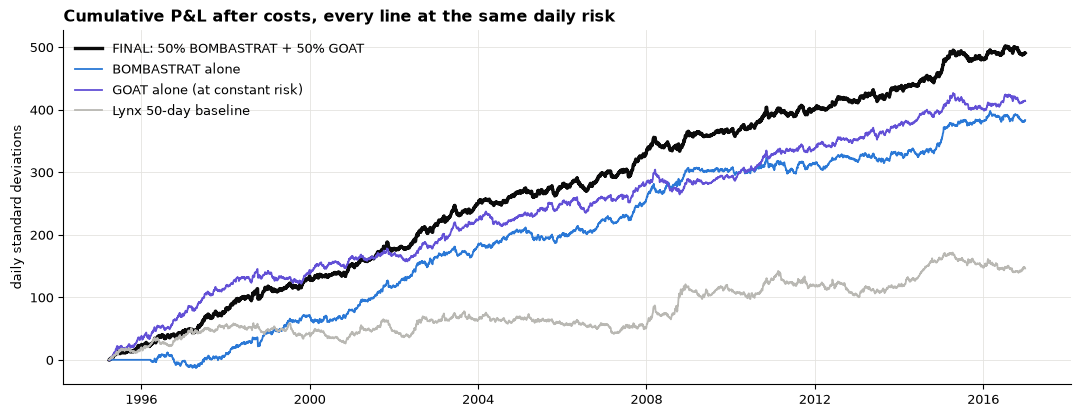

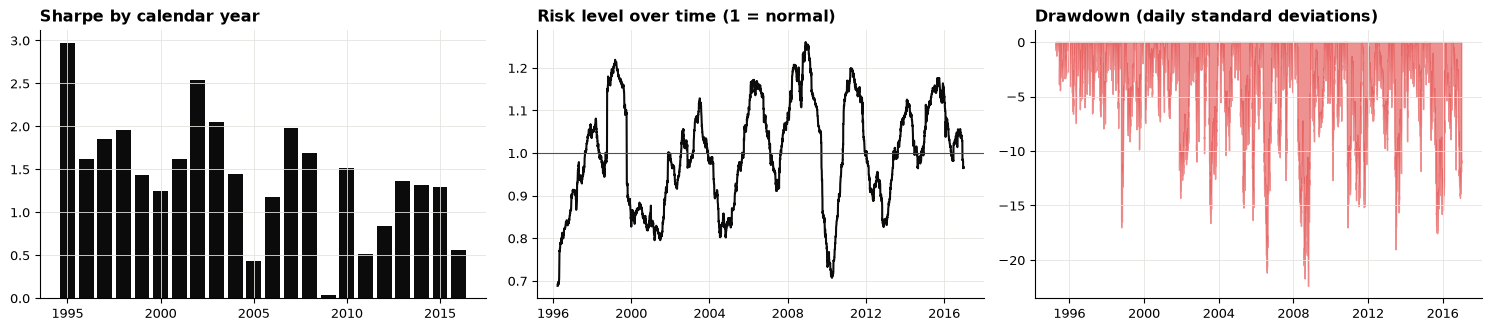

positive calendar years: 22 of 22;  risk range: 0.69x to 1.26x of normal;  worst drawdown: -22 daily standard deviations
OK       risk level stays within 0.6x to 1.6x of normal  
OK       at least 18 of the calendar years are positive  (22 of 22)


In [6]:
RET = pd.DataFrame({k: kf(p, keys=["returns"])["returns"].to_pandas().set_index(DATE)["returns"] for k, p in BOOKS.items()}).iloc[3:]
RET.index = pd.to_datetime(RET.index)
live = RET.loc[RET.iloc[:, 0].ne(0).idxmax():]
COL = ["#0b0b0b", "#2a78d6", "#6250d6", "#b9b8b3"]
fig, ax = plt.subplots(figsize=(13, 4.6))
for (k, r), c in zip(live.items(), COL):
    ax.plot(r.index, (r / r.std()).cumsum(), color=c, lw=2.4 if k.startswith("FINAL") else 1.3, label=k)
ax.set_title("Cumulative P&L after costs, every line at the same daily risk"); ax.set_ylabel("daily standard deviations"); ax.legend(loc="upper left")
plt.show()

r = live.iloc[:, 0]
yearly = r.groupby(r.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(260))
roll_sd = r.rolling(260).std().dropna(); roll_sd = roll_sd / roll_sd.median()
cum = (r / r.std()).cumsum(); dd = cum - cum.cummax()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
axes[0].bar(yearly.index, yearly.values, color=["#0b0b0b" if v > 0 else "#e34948" for v in yearly.values]); axes[0].set_title("Sharpe by calendar year")
axes[1].plot(roll_sd.index, roll_sd, color="#0b0b0b"); axes[1].axhline(1, color="#52514e", lw=0.8); axes[1].set_title("Risk level over time (1 = normal)")
axes[2].fill_between(dd.index, dd, 0, color="#e34948", alpha=0.6); axes[2].set_title("Drawdown (daily standard deviations)")
plt.tight_layout(); plt.show()
print(f"positive calendar years: {(yearly > 0).sum()} of {len(yearly)};  risk range: {roll_sd.min():.2f}x to {roll_sd.max():.2f}x of normal;  worst drawdown: {dd.min():.0f} daily standard deviations")
check("risk level stays within 0.6x to 1.6x of normal", roll_sd.min() > 0.6 and roll_sd.max() < 1.6)
check("at least 18 of the calendar years are positive", (yearly > 0).sum() >= 18, f"({(yearly > 0).sum()} of {len(yearly)})")

## 6. Where the risk and the P&L sit

,assets,share of risk,share if even,share of P&L,average long tilt
bonds,5,0.39,0.19,0.41,0.74
stocks,5,0.26,0.19,0.27,0.71
fx,4,0.06,0.15,0.05,0.29
commodity,13,0.30,0.48,0.27,0.05


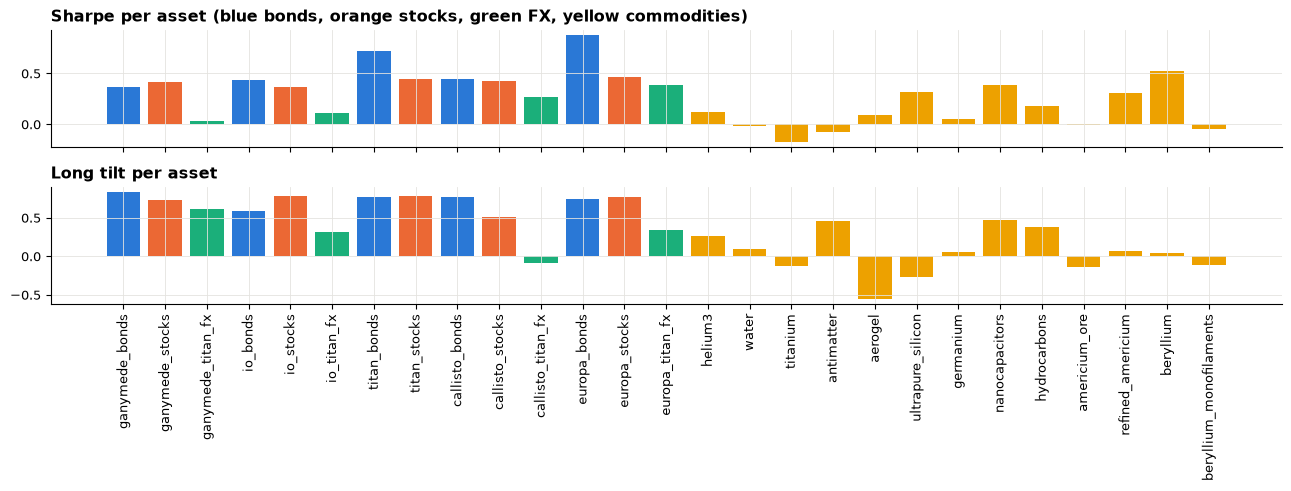

assets with positive P&L: 22 of 27;  largest single-asset share of risk: titan_bonds 9%;  correlation BOMBASTRAT vs GOAT P&L: 0.34
OK       no single asset carries more than 15% of the risk  
OK       at least 20 of 27 assets make money  (22 of 27)


In [7]:
P = as_pd(pos); ap = (P.shift(2) * px_pd.diff()).loc[live.index[0]:]
tot = ap.sum(axis=1); share = ap.apply(lambda x: x.cov(tot)) / tot.var()
cls = pd.Series({a: model.get_sector(a) for a in P.columns})
per = kf(pos, keys=["sharpe_per_instrument", "position_bias_per_instrument"])
by = pd.DataFrame({"assets": cls.value_counts(), "share of risk": share.groupby(cls).sum(), "share if even": cls.value_counts() / len(cls),
                   "share of P&L": ap.sum().groupby(cls).sum() / tot.sum(), "average long tilt": pd.Series(per["position_bias_per_instrument"]).groupby(cls).mean()})
display(by.loc[["bonds", "stocks", "fx", "commodity"]].style.format(precision=2))
cc = {"bonds": "#2a78d6", "stocks": "#eb6834", "fx": "#1baf7a", "commodity": "#eda100"}
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
sh = pd.Series(per["sharpe_per_instrument"]); bi = pd.Series(per["position_bias_per_instrument"])
axes[0].bar(sh.index, sh, color=[cc[cls[a]] for a in sh.index]); axes[0].set_title("Sharpe per asset (blue bonds, orange stocks, green FX, yellow commodities)")
axes[1].bar(bi.index, bi, color=[cc[cls[a]] for a in bi.index]); axes[1].set_title("Long tilt per asset"); axes[1].tick_params("x", rotation=90)
plt.tight_layout(); plt.show()
print(f"assets with positive P&L: {(ap.sum() > 0).sum()} of {len(sh)};  largest single-asset share of risk: {share.idxmax()} {share.max():.0%};  correlation BOMBASTRAT vs GOAT P&L: {live.iloc[:, 1].corr(live.iloc[:, 2]):.2f}")
check("no single asset carries more than 15% of the risk", share.max() < 0.15)
check("at least 20 of 27 assets make money", (ap.sum() > 0).sum() >= 20, f"({(ap.sum() > 0).sum()} of 27)")

## 7. Lynx's own dashboard

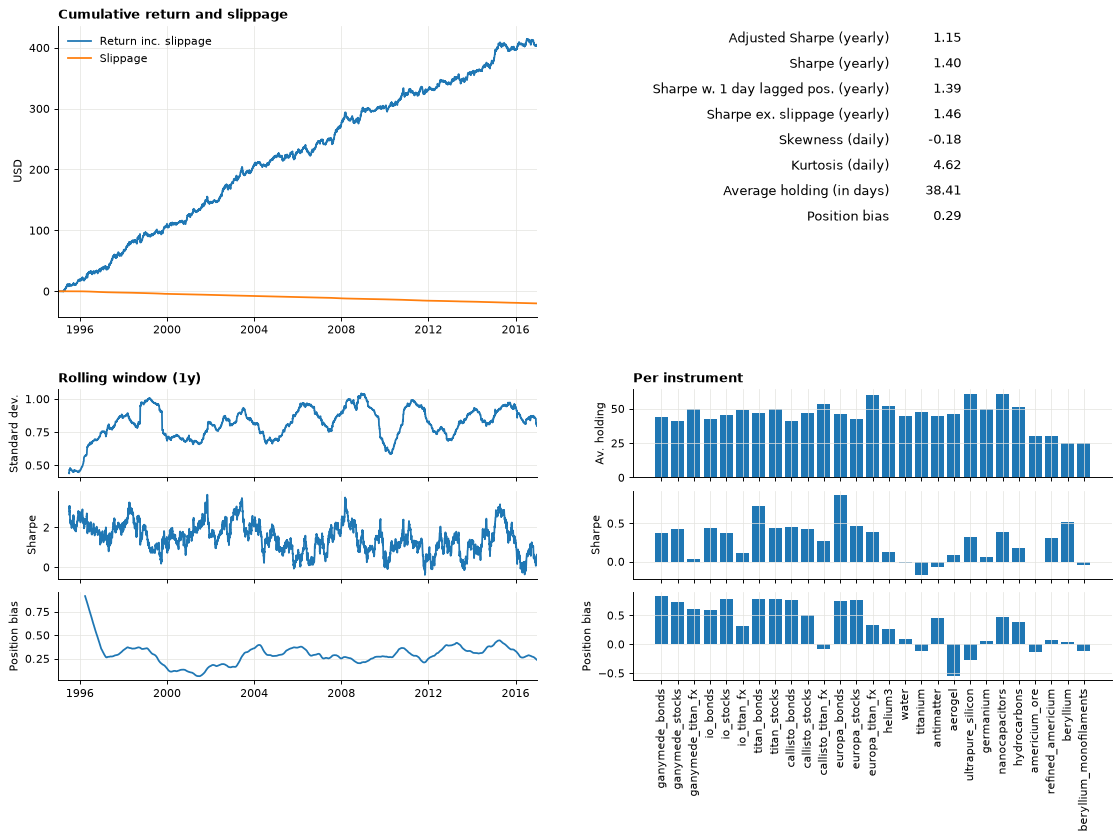

In [8]:
buf = io.BytesIO(); ev.plot_key_figures(pos, prices).savefig(buf, format="png", dpi=85, bbox_inches="tight"); display(Image(buf.getvalue()))

## 8. Verdict

In [9]:
for k, v in CHECKS.items():
    print(f"{'OK     ' if v else 'PROBLEM'}  {k}")
print()
print(f"{sum(CHECKS.values())} of {len(CHECKS)} checks OK" + ("" if all(CHECKS.values()) else "  <-- LOOK AT THE PROBLEM LINES ABOVE"))

OK       model.py is self-contained (no imports from the rest of the repo)
OK       format: AsOfDate + the same 27 asset columns, in the same order as the price file
OK       one row per price date
OK       no missing or infinite values
OK       saved positions_insample.csv equals a fresh run
OK       leak test a) shorter history (cut at 10/30/50/70/90/97%)
OK       leak test b) future replaced by random data (after 30/50/70/90%)
OK       command line with two files (in-sample + 'out-of-sample') equals the single-file run
OK       same with the Open/High/Low/Close price file
OK       adjusted Sharpe matches SUBMISSION/README.md (1.15 on the whole file)
OK       the mix scores at least as high as each half on the whole file
OK       positive in every era
OK       one extra day of lag costs less than 0.05 Sharpe
OK       risk level stays within 0.6x to 1.6x of normal
OK       at least 18 of the calendar years are positive
OK       no single asset carries more than 15% of the risk
OK     

**Reminders for the hand-in**
- The model has a deliberate long tilt (see the table in section 4). Say so in the pitch.
- Do not change `SUBMISSION/model.py` after the out-of-sample data is released. Run the command in `SUBMISSION/README.md`, then `python SUBMISSION/check.py SUBMISSION/positions.csv`.